NAMA : TIARA ANANDA PARDOSI

Klasifikasi teks dipakai untuk mengelompokkan teks ke dalam kategori tertentu.
Klasifikasi teks mulai dari preprocessing teks, ekstraksi fitur, sampai melatih model Naive Bayes untuk mendeteksi pesan spam atau bukan spam.

In [2]:
import pandas as pd
df = pd.read_csv('Text_classification.csv')
print(df.head())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


Penjelasan:
Kode di atas untuk membuka dataset `Text_classification.csv` dan menampilkan 5 baris pertamanya. Dataset ini punya dua kolom, yaitu `Category` yang berisi label (ham atau spam) dan `Message` yang berisi isi pesannya. Ham artinya pesan biasa, sedangkan spam artinya pesan sampah atau iklan yang tidak diinginkan.
NLTK (Natural Language Toolkit) adalah pustaka Python yang membantu komputer menganalisis, memproses, dan memahami teks tertulis. NLTK menyediakan alat untuk tokenisasi, stemming, lemmatization, penghapusan stopword, dan analisis teks lainnya.

In [8]:
# Download resource NLTK yang diperlukan
%pip install nltk
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
# Import library untuk preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()
# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower() # Ubah menjadi lowercase
    text = re.sub(r'\d+', '', text) # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
    words = word_tokenize(text) # Tokenisasi
    words = [word for word in words if word not in stopwords.words('english')] # Hapus stopwords
    words = [lemmatizer.lemmatize(word) for word in words] # Lemmatization
    return ' '.join(words)
# Terapkan preprocessing ke teks
df['clean_text'] = df['Message'].apply(clean_text)
# Cek hasil preprocessing
print("\nHasil Preprocessing:\n", df[['Message', 'clean_text']].head())

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 521.4 kB/s eta 0:00:03
   ----------- ---------------------------- 0.5/1.8 MB 521.4 kB/s eta 0:00:03
   ----------------- ---------------------- 0.8/1.8 MB 534.9 kB/s eta 0:00:02
   ----------------- ---------------------- 0.8/1.8 MB 534.9 kB/s eta 0:00:02
   ----------------------- ---------------- 1.0/1.8 MB 590.5 kB/s eta 0:00:02
   ----------------------- ---------------- 1.0/1.8 MB 590.5 kB/s eta 0:00:02
   ----------------------------- ---------- 1.3/1.8 MB 597.6 kB/s eta 0:00:01
   ----------------------------- -------

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\acer\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\acer\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\acer\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\acer\AppData\Roaming\nltk_data...



Hasil Preprocessing:
                                              Message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


Penjelasan:
Kode di atas untuk membersihkan teks pesan sebelum dipakai untuk melatih model. Komputer tidak bisa langsung memahami teks mentah yang penuh huruf besar, angka, tanda baca, dan kata-kata umum, jadi teks perlu dirapikan dulu.

Bagian awal kode mengunduh resource yang dibutuhkan NLTK, yaitu `punkt` dan `punkt_tab` untuk memecah teks menjadi kata, `stopwords` untuk daftar kata umum, dan `wordnet` untuk kamus kata dasar. Setelah itu library yang diperlukan di-import dan `WordNetLemmatizer` disiapkan.

Inti kodenya ada di fungsi `clean_text`, yang menjalankan beberapa langkah pembersihan secara berurutan. Teks diubah menjadi huruf kecil semua supaya kata seperti "Free" dan "free" dianggap sama. Angka dihapus dengan `re.sub(r'\d+', '', text)`. Tanda baca dihapus dengan `translate`. Teks lalu dipecah menjadi kata-kata per kata (tokenisasi) dengan `word_tokenize`. Kata-kata umum seperti "the", "is", dan "to" yang disebut stopwords dibuang karena tidak membantu membedakan spam dan ham. Terakhir, lemmatization mengubah kata ke bentuk dasarnya, misalnya "lives" menjadi "life" atau "going" menjadi "go", lalu kata-katanya digabung lagi menjadi satu kalimat dengan `' '.join(words)`.

Fungsi itu diterapkan ke seluruh kolom `Message` dengan `.apply(clean_text)`, dan hasilnya disimpan di kolom baru `clean_text`. Dari output-nya terlihat perubahannya, misalnya pesan "Ok lar... Joking wif u oni..." menjadi "ok lar joking wif u oni".

Proses ini bisa memakan waktu beberapa saat karena ada ribuan pesan yang diproses satu per satu.

In [9]:
# Ubah label dari 'ham'/'spam' menjadi 0/1
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})
# Cek jumlah masing-masing kelas
print(df['Category'].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


Penjelasan:
Kode di atas untuk mengubah label dari tulisan menjadi angka, yaitu ham menjadi 0 dan spam menjadi 1. Model machine learning bekerja dengan angka, jadi label berupa teks perlu diubah dulu. Setelah itu `value_counts()` dipakai untuk menghitung jumlah data di tiap kelas.

Hasilnya, ada 4825 pesan ham dan 747 pesan spam. Artinya datanya tidak seimbang karena pesan ham jauh lebih banyak daripada spam. Hal ini perlu diingat saat membaca hasil evaluasi nanti, dan juga alasan kenapa pada pembagian data berikutnya dipakai `stratify`.

In [10]:
from sklearn.model_selection import train_test_split
# Pisahkan fitur dan label
X = df['clean_text']
y = df['Category']
# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Penjelasan:
Kode di atas untuk memisahkan fitur dan label, lalu membagi data menjadi data latih dan data uji. `X` berisi teks yang sudah dibersihkan (bahan untuk menebak) dan `y` berisi label 0 atau 1 (jawaban yang mau ditebak).

Data dibagi dengan `train_test_split` dengan porsi 80% untuk melatih model dan 20% untuk menguji model. `random_state=42` dipakai supaya pembagian datanya selalu sama setiap kali kode dijalankan ulang. Parameter `stratify=y` membuat perbandingan spam dan ham di data latih dan data uji sama dengan data aslinya. Ini penting karena jumlah spam jauh lebih sedikit, jadi tanpa `stratify` bisa saja data uji hampir tidak berisi spam.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), max_features=5000) # Menggunakan bigram
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print("\nTF-IDF Shape (Train):", X_train_tfidf.shape)


TF-IDF Shape (Train): (4457, 5000)


#### Penjelasan:
Kode di atas untuk mengubah teks menjadi angka memakai TF-IDF, karena model tidak bisa memproses teks secara langsung. TF-IDF memberi bobot pada setiap kata. Kata yang sering muncul di satu pesan tetapi jarang muncul di pesan lain akan mendapat bobot tinggi, sedangkan kata yang muncul di hampir semua pesan mendapat bobot rendah.

Pengaturan `ngram_range=(1,2)` membuat model memperhatikan kata tunggal (unigram) dan juga pasangan dua kata berurutan (bigram), misalnya "free entry". `max_features=5000` membatasi jumlah fitur menjadi 5000 kata atau pasangan kata yang paling penting.

Perhatikan bahwa data latih memakai `fit_transform`, sedangkan data uji hanya memakai `transform`. Artinya vectorizer belajar kosakata dan bobotnya dari data latih saja, lalu data uji diubah dengan aturan yang sama. Dengan begitu data uji benar-benar tidak ikut memengaruhi proses belajar.

Hasilnya `(4457, 5000)`, yang artinya ada 4457 pesan latih dan masing-masing diwakili oleh 5000 angka.

In [12]:
from sklearn.naive_bayes import MultinomialNB
# Inisialisasi model Naïve Bayes
model = MultinomialNB(alpha=0.1)
# Train model
model.fit(X_train_tfidf, y_train)
# Prediksi hasil
y_pred = model.predict(X_test_tfidf)

#### Penjelasan:
Kode di atas untuk membuat dan melatih model Naive Bayes, lalu memakainya untuk memprediksi data uji. `MultinomialNB` adalah jenis Naive Bayes yang cocok untuk data berupa hitungan atau bobot kata, sehingga sering dipakai untuk klasifikasi teks. Parameter `alpha=0.1` mengatur smoothing, yaitu supaya kata yang belum pernah muncul di salah satu kelas tidak membuat peluangnya jadi nol.

`model.fit(X_train_tfidf, y_train)` adalah proses belajarnya, di mana model mempelajari kata-kata apa saja yang sering muncul di pesan spam dan di pesan ham. Setelah itu `model.predict(X_test_tfidf)` dipakai untuk menebak label pesan di data uji, dan hasil tebakannya disimpan di `y_pred`.

In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)
# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.979372197309417

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



#### Penjelasan:
Kode di atas untuk mengukur seberapa bagus model menebak, dengan membandingkan tebakan model (`y_pred`) dengan jawaban sebenarnya (`y_test`). Akurasi menunjukkan persentase tebakan yang benar. Di modul, akurasinya sekitar 0.979, artinya sekitar 98% pesan di data uji berhasil ditebak dengan benar.

Akurasi saja bisa menyesatkan pada data yang tidak seimbang, karena itu dipakai juga classification report. Di dalamnya ada precision, yaitu dari semua pesan yang ditebak spam, berapa persen yang memang spam. Ada recall, yaitu dari semua pesan spam yang sebenarnya, berapa persen yang berhasil ditemukan model. Ada juga f1-score, yaitu nilai gabungan precision dan recall, dan support, yaitu jumlah data sebenarnya di tiap kelas.

Di modul, kelas ham (0) punya precision 0.98 dan recall 1.00, sedangkan kelas spam (1) punya precision 0.98 dan recall 0.86. Artinya model sangat jarang salah menuduh pesan biasa sebagai spam, tetapi masih ada sekitar 14% pesan spam yang lolos dan terbaca sebagai ham.

Angka yang muncul di notebook kamu bisa sedikit berbeda dari angka di modul, karena dipengaruhi versi library yang dipakai.

Confusion matrix adalah tabel evaluasi yang menunjukkan bagaimana model klasifikasi bekerja dalam memprediksi kelas data. Istilah yang dipakai di dalamnya adalah True Positive (TP) yaitu model benar memprediksi spam sebagai spam, True Negative (TN) yaitu model benar memprediksi ham sebagai ham, False Positive (FP) yaitu model salah memprediksi ham sebagai spam, dan False Negative (FN) yaitu model salah memprediksi spam sebagai ham.

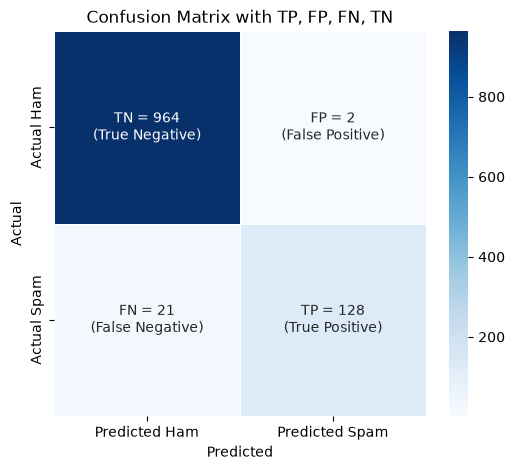

In [17]:
# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
# Definisi elemen dalam confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()
# Buat dataframe confusion matrix
df_conf_matrix = pd.DataFrame(conf_matrix, index=['Actual Ham', 'Actual Spam'], columns=['Predicted Ham', 'Predicted Spam'])
# Label untuk TP, FP, FN, TN
labels = np.array([["TN = {}\n(True Negative)".format(TN), "FP = {}\n(False Positive)".format(FP)],
                   ["FN = {}\n(False Negative)".format(FN), "TP = {}\n(True Positive)".format(TP)]])
# Plot heatmap dengan keterangan
plt.figure(figsize=(6,5))
ax = sns.heatmap(df_conf_matrix, annot=labels, fmt='', cmap='Blues', linewidths=0.5, cbar=True)
# Tambahkan label
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with TP, FP, FN, TN')
plt.show()

#### Penjelasan:
Kode di atas untuk menampilkan confusion matrix dalam bentuk gambar heatmap, supaya lebih mudah dilihat daripada deretan angka. `confusion_matrix(y_test, y_pred)` menghitung berapa banyak pesan yang ditebak benar dan salah untuk tiap kelas. Hasilnya berupa tabel 2x2 yang kemudian dipecah dengan `.ravel()` menjadi empat angka, yaitu TN, FP, FN, dan TP.

Empat angka itu dimasukkan ke DataFrame dengan label baris Actual Ham dan Actual Spam, serta label kolom Predicted Ham dan Predicted Spam. Array `labels` dipakai supaya setiap kotak di heatmap menampilkan nama dan jumlahnya sekaligus, misalnya "TN = 963 (True Negative)". Kemudian `sns.heatmap` menggambar tabelnya dengan warna biru, di mana warna yang lebih gelap menunjukkan jumlah yang lebih besar.

Cara membacanya, kotak di diagonal (kiri atas dan kanan bawah) adalah tebakan yang benar, sedangkan dua kotak lainnya adalah kesalahan model. Kotak FP berisi ham yang salah dikira spam, dan kotak FN berisi spam yang lolos karena dikira ham. Pada modul ini FN lebih besar daripada FP, sesuai dengan recall spam yang lebih rendah di classification report.

In [18]:
# Contoh teks baru
new_texts = ["Congratulations! You won a free trip to Bali.",
"Hey, are you coming to the party tonight?"]
# Preprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]
# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer.transform(new_texts_clean)
# Prediksi
predictions = model.predict(new_texts_tfidf)
# Output hasil prediksi
for text, label in zip(new_texts, predictions):
    print(f"\nMessage: {text} \nPredicted: {'Spam' if label == 1 else 'Ham'}")


Message: Congratulations! You won a free trip to Bali. 
Predicted: Spam

Message: Hey, are you coming to the party tonight? 
Predicted: Ham


#### Penjelasan:
Kode di atas untuk mencoba model yang sudah dilatih pada dua pesan baru yang belum pernah dilihat sebelumnya. Pesan pertama berisi ucapan selamat dan hadiah gratis, sedangkan pesan kedua berisi ajakan ke pesta yang terdengar seperti percakapan biasa.

Setiap pesan baru harus melewati tahapan yang sama seperti data latih. Pesan dibersihkan dulu dengan `clean_text`, lalu diubah menjadi angka dengan `vectorizer.transform` (memakai `transform` saja, bukan `fit_transform`, supaya memakai kosakata yang sudah dipelajari dari data latih), baru dimasukkan ke `model.predict`. Kalau tahapannya berbeda, model tidak akan mengenali bentuk datanya.

Di bagian akhir, hasil prediksi 1 ditampilkan sebagai Spam dan 0 sebagai Ham. Di modul, pesan pertama diprediksi Spam dan pesan kedua diprediksi Ham, sesuai dengan yang kita harapkan.